# Evaluación de la generación LLM: fidelidad y relevancia

En [`02_evaluacion_rag.ipynb`](02_evaluacion_rag.ipynb) medimos únicamente el **retrieval**: si la técnica correcta aparecía en el Top-5. Este notebook da el paso siguiente y evalúa la **respuesta final** del LLM.

La pregunta que responde es:

> Dada una alerta de Wazuh y el contexto MITRE recuperado, ¿la respuesta del analista LLM se sostiene en ese contexto (**fidelidad**) y atiende realmente la consulta (**relevancia**)?

A diferencia de la evaluación de retrieval, acá no hay una única etiqueta correcta: una respuesta puede ser correcta, estar bien fundamentada, o ambas cosas. Por eso se combinan:

- **Puntuación manual con rúbrica** de fidelidad y relevancia (la fuente oficial del resultado).
- **Chequeos automáticos objetivos** (técnica principal, IDs fuera del contexto, latencia) que sirven de contraste.

**Alcance:** una sola corrida sobre las mismas **31 alertas** que cubren **17 técnicas MITRE** (25 reglas únicas). Los promedios son frágiles y se reportan con IC del 95 %.


## 1. Qué se mide y por qué la puntuación es manual

### Fidelidad (*Faithfulness*)

Una respuesta es fiel si **todas sus afirmaciones técnicas están respaldadas por el contexto recuperado**. En este caso el contexto son las 5 técnicas MITRE que devolvió el RAG, con su nombre, táctica y descripción.

La fidelidad **no** premia que la respuesta sea correcta: si el LLM acierta la técnica pero esa técnica no estaba en el contexto, la respuesta no está fundamentada y la fidelidad debe bajar. Ese es justamente el riesgo que queremos detectar: que el modelo responda de memoria en lugar de apoyarse en el RAG.

### Relevancia de la respuesta (*Answer Relevance*)

Una respuesta es relevante si **atiende la consulta del analista**: identifica la técnica más probable, justifica la elección con el texto de la alerta y propone acciones de triaje concretas. La relevancia no exige que la técnica sea la correcta; para eso están los chequeos automáticos de acierto.

### ¿Por qué no usamos un juez LLM?

Porque en este trabajo **la evaluación la hace una persona**: vos. Un juez automático del mismo modelo que genera la respuesta introduce sesgo de autopreferencia, y con 31 respuestas la anotación manual es perfectamente abordable. La rúbrica de la sección 7 deja explícitos los criterios para que la puntuación sea reproducible.

La automatización con [Ragas](https://docs.ragas.io/) o un juez LLM independiente queda como trabajo futuro; estos puntajes manuales servirían para validar ese juez.

Tambien, no cuento con modelos pagos asi que tengo que cuidar los tokens de modelos free que uso en este proyecto


In [13]:
import ast
import json
import re
import time
from pathlib import Path

import pandas as pd
from langchain_core.prompts import ChatPromptTemplate
from langsmith import Client
from langsmith.evaluation import evaluate
from pydantic import BaseModel, Field

from capazeta.config import MODEL_NAME
from capazeta.llm import get_llm

ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()
)
TESTS = ROOT / "tests"
REPORTS = ROOT / "reports"
MITRE_DIR = ROOT / "data" / "mitre"

DATASET_NAME = "Evaluacion_LLM_Capazeta"
PREGUNTA = (
    "¿Qué técnica MITRE ATT&CK corresponde a esta alerta de Wazuh, por qué, "
    "y qué acciones de triaje recomendás?"
)

print("Raíz del repo:", ROOT)
print("Modelo generador:", MODEL_NAME)


Raíz del repo: /home/joaquincernik/Desktop/ia/final
Modelo generador: google_genai:gemini-3.1-flash-lite


In [14]:
gt = pd.read_csv(TESTS / "wazuh_ground_truth_annoted.csv")
gemini = pd.read_csv(REPORTS / "evaluacion_capazeta_rag_gemini-embedding-001.csv")

df = gt.merge(
    gemini,
    left_on=["rule.description", "mitre_id"],
    right_on=["inputs.rule.description", "reference.mitre_id"],
    how="inner",
    validate="one_to_one",
)

df = df.rename(
    columns={
        "rule.description": "alerta",
        "outputs.tecnicas_recuperadas": "tecnicas_recuperadas_str",
        "feedback.hit@5": "hit5_retrieval",
        "feedback.mrr": "mrr_retrieval",
        "id": "run_retrieval_id",
    }
)
df["contexto_ids"] = df["tecnicas_recuperadas_str"].apply(ast.literal_eval)
df["pregunta"] = PREGUNTA

assert len(df) == 31, f"Se esperaban 31 alertas y llegaron {len(df)}"
assert df["alerta"].is_unique, "Hay descripciones de alerta duplicadas"

columnas = [
    "alerta",
    "mitre_id",
    "mitre_technique",
    "mitre_tactic",
    "hit5_retrieval",
    "contexto_ids",
]
print(f"Alertas listas para evaluar: {len(df)}")
df[columnas].head(5)


Alertas listas para evaluar: 31


,alerta,mitre_id,mitre_technique,mitre_tactic,hit5_retrieval,contexto_ids
0,Audit: Command: /usr/bin/ps.,T1057,Process Discovery,Discovery,1.0,"[T1057, T1003.007, T1685.004, T1036.011, T1055..."
1,Audit: Watch - Read access: /etc/shadow.,T1003.008,OS Credential Dumping: /etc/passwd and /etc/sh...,Credential Access,1.0,"[T1003.008, T1556.003, T1685.004, T1548.003, T..."
2,Audit: Watch - Read access: shadow.,T1003.008,OS Credential Dumping: /etc/passwd and /etc/sh...,Credential Access,1.0,"[T1003.008, T1006, T1556.003, T1207, T1685.004]"
3,Integrity checksum changed.,T1565.001,Data Manipulation: Stored Data Manipulation,Impact,1.0,"[T1027.001, T1036.001, T1553.006, T1565.001, T..."
4,Audit: Watch - Read access.,T1003.008,OS Credential Dumping: /etc/passwd and /etc/sh...,Credential Access,1.0,"[T1685.004, T1006, T1003.008, T1685.001, T1222]"


In [15]:
with open(MITRE_DIR / "techniques.json", encoding="utf-8") as f:
    TECNICAS = json.load(f)


def contexto_desde_ids(ids, max_desc: int = 600) -> str:
    """Arma el contexto legible que recibe el LLM a partir de los IDs recuperados."""
    bloques = []
    for tid in ids:
        info = TECNICAS.get(tid)
        if not info:
            bloques.append(f"[{tid}] (ID no encontrado en techniques.json)")
            continue
        tacticas = ", ".join(info.get("tactics") or []) or "sin táctica declarada"
        descripcion = " ".join((info.get("description") or "").split())
        bloques.append(
            f"[{tid}] {info.get('name', '')} | Tácticas: {tacticas} | {info.get('url', '')}\n"
            f"Descripción: {descripcion[:max_desc]}"
        )
    return "\n\n".join(bloques)


print(f"Técnicas cargadas: {len(TECNICAS)}")
print("Ejemplo de contexto para la primera alerta:\n")
print(contexto_desde_ids(df.loc[0, "contexto_ids"]))


Técnicas cargadas: 867
Ejemplo de contexto para la primera alerta:

[T1057] Process Discovery | Tácticas: Discovery | https://attack.mitre.org/techniques/T1057/
Descripción: Adversaries may attempt to get information about running processes on a system. Information obtained could be used to gain an understanding of common software/applications running on systems within the network. Administrator or otherwise elevated access may provide better process details. Adversaries may use the information from [Process Discovery](https://attack.mitre.org/techniques/T1057) during automated discovery to shape follow-on behaviors, including whether or not the adversary fully infects the target and/or attempts specific actions. In Windows environments, adversaries could obtain d

[T1003.007] Proc Filesystem | Tácticas: Credential Access | https://attack.mitre.org/techniques/T1003/007/
Descripción: Adversaries may gather credentials from the proc filesystem or `/proc`. The proc filesystem is a pseudo-

## 2. Prompt de generación

El prompt tiene dos objetivos:

1. **Forzar el anclaje al contexto:** el modelo solo puede elegir técnicas que aparezcan en los 5 documentos recuperados. Si no alcanza, debe decirlo.
2. **Producir una respuesta evaluable:** técnica principal, justificación y 2 o 3 acciones de triaje.

Usamos salida estructurada (`with_structured_output`) para separar la técnica elegida del texto libre. Eso permite calcular el acierto de forma determinista sin depender de parsear.


In [ ]:
class RespuestaAnalisis(BaseModel):
    """Salida estructurada del analista LLM."""

    tecnica_principal: str = Field(
        description=(
            "ID de la técnica MITRE más probable según el contexto, "
            "por ejemplo T1110.001."
        )
    )
    respuesta: str = Field(
        description=(
            "Análisis completo en español: técnica elegida, justificación basada "
            "en la alerta y 2 o 3 acciones de triaje concretas. Debe citar solo "
            "IDs presentes en el contexto."
        )
    )


PROMPT = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            """Sos un analista de SOC experto en MITRE ATT&CK. Respondés en español, con precisión técnica y enfoque defensivo y ético.

Reglas obligatorias:
1. Usá únicamente el CONTEXTO MITRE provisto para elegir la técnica. No inventes IDs, nombres ni tácticas.
2. Si el contexto no permite decidir con certeza, elegí la opción más probable del contexto y aclaralo en la respuesta.
3. Justificá la elección conectando el texto de la alerta con la descripción de la técnica.
4. Proponé 2 o 3 acciones de triaje concretas y verificables.
5. No pidas permisos ni agregues avisos genéricos.""",
        ),
        (
            "human",
            """Alerta de Wazuh:
{alerta}

Pregunta del analista:
{pregunta}

CONTEXTO MITRE (Top-5 recuperado por el RAG):
{contexto}""",
        ),
    ]
)

llm = get_llm()
llm_estructurado = llm.with_structured_output(RespuestaAnalisis)
print("Modelo generador:", MODEL_NAME)


## 3. Pipeline evaluado

El pipeline es una **cadena RAG aislada**:

```text
alerta + Top-5 ya recuperado por Gemini
        ↓
contexto legible (ID, nombre, táctica, descripción, URL)
        ↓
prompt + LLM con salida estructurada
        ↓
respuesta + técnica principal + latencia
```

No se invoca el router ni las tools del agente: así medimos la generación y no el ruteo. Tampoco se vuelve a consultar FAISS: el contexto se toma del CSV de la corrida de Gemini que ya se evaluó con Hit@5/MRR. Eso hace que el experimento sea reproducible aunque cambie el `EMBEDDING_MODEL` del `.env`.


In [ ]:
def capazeta_llm_rag_pipeline(inputs: dict) -> dict:
    """Cadena RAG aislada: contexto ya recuperado + prompt + LLM."""
    alerta = inputs["rule.description"]
    ids = list(inputs["contexto_ids"])
    contexto = contexto_desde_ids(ids)

    inicio = time.perf_counter()
    salida = llm_estructurado.invoke(
        PROMPT.format_messages(
            alerta=alerta,
            pregunta=inputs.get("pregunta", PREGUNTA),
            contexto=contexto,
        )
    )
    latencia = time.perf_counter() - inicio

    return {
        "respuesta": salida.respuesta,
        "tecnica_principal": salida.tecnica_principal.strip(),
        "contexto_ids": ids,
        "contexto_texto": contexto,
        "modelo": MODEL_NAME,
        "latencia_s": round(latencia, 3),
    }


### Smoke test antes de gastar 31 llamadas

Probamos el pipeline con las dos primeras alertas. Revisamos que la respuesta cite solo IDs del contexto y que tenga acciones de triaje. Si algo falla (por ejemplo, el modelo no soporta salida estructurada), se arregla acá y no después de la corrida completa.


In [ ]:
for i in [0, 1]:
    fila = df.iloc[i]
    salida = capazeta_llm_rag_pipeline(
        {
            "rule.description": fila["alerta"],
            "pregunta": PREGUNTA,
            "contexto_ids": fila["contexto_ids"],
        }
    )
    print("=" * 90)
    print("ALERTA:", fila["alerta"])
    print("TÉCNICA ESPERADA:", fila["mitre_id"], "—", fila["mitre_technique"])
    print("TÉCNICA PRINCIPAL:", salida["tecnica_principal"])
    print("LATENCIA:", salida["latencia_s"], "s")
    print("\nRESPUESTA:\n", salida["respuesta"])


## 4. Dataset en LangSmith

Subimos las 31 alertas a un dataset propio. Cada ejemplo guarda:

- **Inputs:** descripción de la alerta, pregunta del analista y el Top-5 recuperado (`contexto_ids`).
- **Outputs de referencia:** `mitre_id`, nombre y táctica de la técnica esperada, más las notas de la anotación original (por ejemplo, técnicas alternativas).

La celda es idempotente: si el dataset ya existe con 31 ejemplos lo reutiliza; si existe con otra cantidad, se detiene para no duplicar datos.


In [ ]:
client = Client()

ejemplos = []
for _, fila in df.iterrows():
    notas = "" if pd.isna(fila["notes"]) else str(fila["notes"])
    ejemplos.append(
        {
            "inputs": {
                "rule.description": fila["alerta"],
                "pregunta": PREGUNTA,
                "contexto_ids": fila["contexto_ids"],
            },
            "outputs": {
                "mitre_id": fila["mitre_id"],
                "mitre_technique": fila["mitre_technique"],
                "mitre_tactic": fila["mitre_tactic"],
                "notes": notas,
            },
        }
    )

if client.has_dataset(dataset_name=DATASET_NAME):
    dataset = client.read_dataset(dataset_name=DATASET_NAME)
    n_existentes = len(list(client.list_examples(dataset_id=dataset.id)))
    if n_existentes != len(ejemplos):
        raise ValueError(
            f"El dataset '{DATASET_NAME}' ya existe con {n_existentes} ejemplos y "
            f"se esperaban {len(ejemplos)}. Revisalo en LangSmith antes de continuar "
            "para no duplicar datos."
        )
    print(f"Dataset '{DATASET_NAME}' ya existe con {n_existentes} ejemplos; se reutiliza.")
else:
    dataset = client.create_dataset(
        dataset_name=DATASET_NAME,
        description=(
            "31 alertas de Wazuh con la técnica MITRE de referencia y el Top-5 "
            "recuperado por Gemini, para evaluar fidelidad y relevancia de la "
            "respuesta del LLM."
        ),
    )
    client.create_examples(dataset_id=dataset.id, examples=ejemplos)
    print(f"Dataset '{DATASET_NAME}' creado con {len(ejemplos)} ejemplos.")


## 5. Ejecución del experimento

Corremos `evaluate` **sin evaluadores**: LangSmith registra la corrida y las trazas, pero no calcula métricas.

Igual que en la evaluación de retrieval, se usa **una sola corrida** (`num_repetitions=1`) y `max_concurrency=2` para no saturar la API.


In [ ]:
resultados = evaluate(
    capazeta_llm_rag_pipeline,
    data=DATASET_NAME,
    evaluators=None,
    experiment_prefix="Capazeta_LLM_RAG",
    description=(
        "Generación LLM sobre 31 alertas; fidelidad y relevancia se puntúan "
        "con rúbrica manual."
    ),
    num_repetitions=1,
    max_concurrency=2,
)

df_raw = resultados.to_pandas()
ruta_raw = REPORTS / "evaluacion_llm_respuestas_raw.csv"
df_raw.to_csv(ruta_raw, index=False, encoding="utf-8-sig")
print(f"Resultados crudos guardados en {ruta_raw} ({len(df_raw)} filas).")

Vemos que se creo correctamente

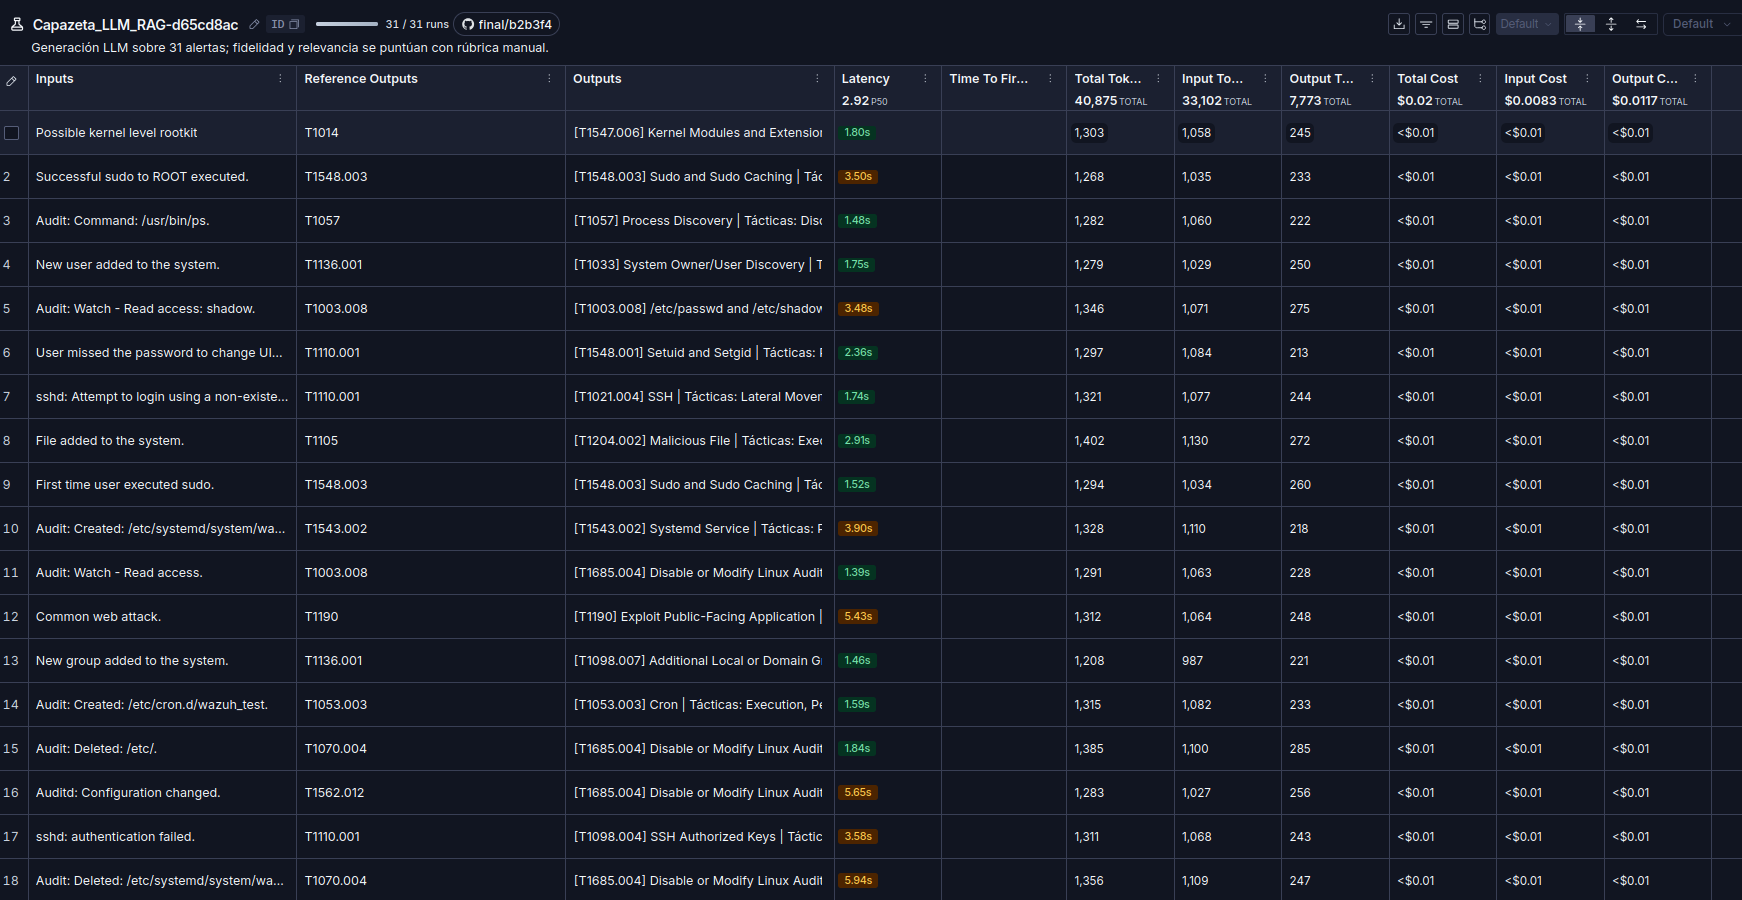

## 6. Puntuación en LangSmith (vía principal)

La forma recomendada de puntuar es la **annotation queue** de LangSmith. La celda siguiente:

1. Crea dos *feedback configs* continuos de 1 a 5 (`fidelidad` y `relevancia`) con las etiquetas de la rúbrica de la sección 7.
2. Reutiliza o crea la cola `Revisión manual LLM - Capazeta`.
3. Agrega a la cola los runs de esta corrida, solo si todavía no están.

Después de correrla, abrimos en LangSmith **Annotation Queues → Revisión manual LLM - Capazeta** y puntuá cada run de 1 a 5. Cuando termines, descargá el **CSV** de la cola desde LangSmith (botón **Export**), guardalo en `reports/` y corré la sección 11. La descarga es manual: el notebook no baja puntajes por API, solo lee el archivo local.

La celda es idempotente: podés correrla varias veces sin duplicar configs, cola ni runs. Si un feedback config ya existe con otra escala, la celda se detiene con un mensaje para corregirlo antes de seguir.


In [ ]:
CONFIGURAR_LANGSMITH = False
QUEUE_NAME = "Revisión manual LLM - Capazeta"

RUBRICA = {
    "fidelidad": {
        "descripcion": "¿Todas las afirmaciones técnicas están respaldadas por el contexto?",
        "etiquetas": {
            1: "Inventa o contradice el contexto",
            2: "Varias afirmaciones centrales sin respaldo",
            3: "Mezcla afirmaciones respaldadas y no respaldadas",
            4: "Casi todo respaldado, con detalles menores",
            5: "Todo respaldado por el contexto",
        },
    },
    "relevancia": {
        "descripcion": "¿La respuesta atiende la alerta y propone triaje accionable?",
        "etiquetas": {
            1: "No responde o deriva a otro tema",
            2: "Tangencial, no ayuda al triaje",
            3: "Responde al tema pero vago",
            4: "Responde bien, con justificación o triaje incompletos",
            5: "Técnica + justificación + triaje accionable",
        },
    },
}


def _escala_1a5(config) -> bool:
    """True si el feedback config ya es continuo de 1 a 5."""
    return (
        getattr(config, "type", None) == "continuous"
        and getattr(config, "min", None) == 1
        and getattr(config, "max", None) == 5
    )


if CONFIGURAR_LANGSMITH:
    existentes = {
        c.feedback_key: c
        for c in client.list_feedback_configs(feedback_key=list(RUBRICA))
    }
    for clave, datos in RUBRICA.items():
        if clave in existentes:
            if not _escala_1a5(existentes[clave].feedback_config):
                cfg = existentes[clave].feedback_config
                raise ValueError(
                    f"El feedback config '{clave}' ya existe con otra escala "
                    f"(type={getattr(cfg, 'type', None)}, "
                    f"min={getattr(cfg, 'min', None)}, "
                    f"max={getattr(cfg, 'max', None)}). "
                    f"Borralo con client.delete_feedback_config('{clave}') "
                    "o usá otra clave antes de continuar."
                )
            print(f"Feedback config '{clave}' ya existe (1–5); se reutiliza.")
        else:
            client.create_feedback_config(
                clave,
                feedback_config={
                    "type": "continuous",
                    "min": 1,
                    "max": 5,
                    "categories": [
                        {"value": valor, "label": etiqueta}
                        for valor, etiqueta in datos["etiquetas"].items()
                    ],
                },
                is_lower_score_better=False,
            )
            print(f"Feedback config '{clave}' creado (1–5).")

    rubric_items = [
        {
            "feedback_key": clave,
            "description": datos["descripcion"],
            "score_descriptions": {
                str(valor): etiqueta
                for valor, etiqueta in datos["etiquetas"].items()
            },
            "is_required": True,
        }
        for clave, datos in RUBRICA.items()
    ]

    instrucciones = (
        "Puntuá cada respuesta de 1 a 5. Fidelidad: solo lo que sostiene el "
        "contexto. Relevancia: qué tan bien atiende la alerta y propone "
        "triaje. Dejá vacío si hubo un error."
    )
    descripcion = (
        "Fidelidad y relevancia de las respuestas del LLM sobre 31 alertas "
        "de Wazuh."
    )

    cola = next(client.list_annotation_queues(name=QUEUE_NAME), None)
    if cola is None:
        cola = client.create_annotation_queue(
            name=QUEUE_NAME,
            description=descripcion,
            rubric_instructions=instrucciones,
            rubric_items=rubric_items,
        )
        print(f"Cola '{QUEUE_NAME}' creada.")
    else:
        client.update_annotation_queue(
            cola.id,
            description=descripcion,
            rubric_instructions=instrucciones,
            rubric_items=rubric_items,
        )
        print(f"Cola '{QUEUE_NAME}' ya existe; se reutiliza y se actualiza el rubric.")

    run_ids = [str(r) for r in df_raw["id"].dropna().tolist()]
    ya_en_cola = {
        str(run.id)
        for run in client.list_runs_from_annotation_queue(cola.id)
    }
    faltantes = [run_id for run_id in run_ids if run_id not in ya_en_cola]
    if faltantes:
        client.add_runs_to_annotation_queue(cola.id, run_ids=faltantes)
    print(
        f"Runs en la cola: {len(ya_en_cola) + len(faltantes)} "
        f"(agregados ahora: {len(faltantes)})."
    )
    print(f"Cola id: {cola.id}")
else:
    print(
        "Configuración de LangSmith desactivada. "
        "Poné CONFIGURAR_LANGSMITH = True para crearla."
    )



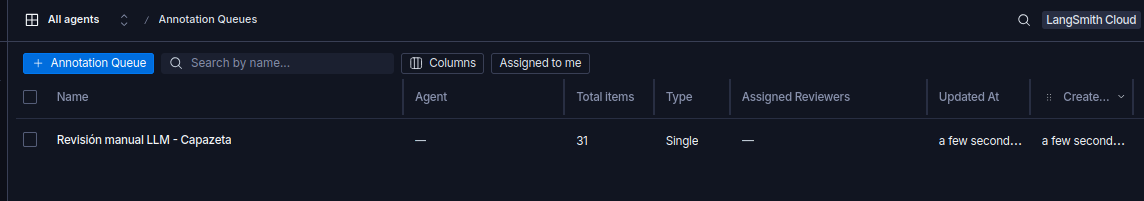

Vemos que se creo correctamente

Y ahora tendremos que ir puntuando la respuesta del LLM en la seccion de feedback rubric


<div align="center">
  <img src="./img/07_evaluacion_llm/image copy.png" width="1200" alt="Prueba de agentes conectados en consola" />
</div>

Vemos que incluso langsmith nos permite dejar annotations, si queremos aportar algun comentario extra

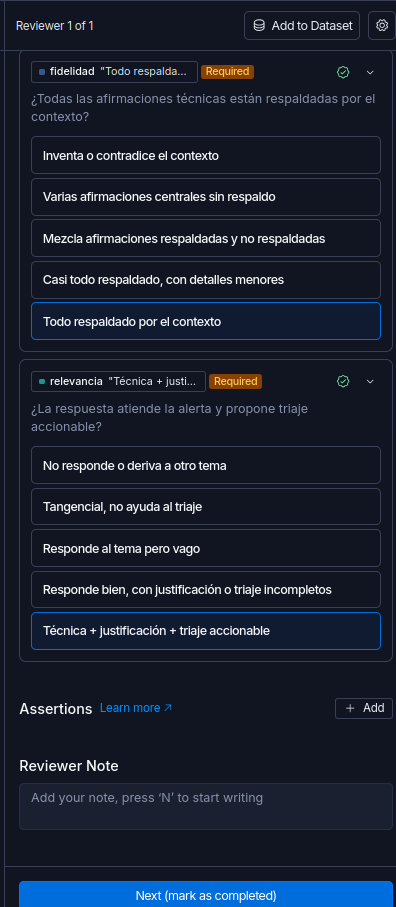

Una vez que terminemos veremos la siguiente tabla con sus respectivos puntajes:
<div align="center">
  <img src="./img/07_evaluacion_llm/image copy 2.png" width="1200" alt="Prueba de agentes conectados en consola" />
</div>

## 7. Rúbrica de puntuación

Puntuaremos cada respuesta de **1 a 5** mirando la fila completa. Para fidelidad, comparamos la respuesta **solo contra el contexto** (no contra la técnica esperada). Para relevancia, miramos la alerta, la técnica de referencia y la utilidad del triaje. Si hubo un error de ejecución o la respuesta está vacía, dejamos el puntaje en blanco.

| Puntaje | Fidelidad | Relevancia |
| :---: | :--- | :--- |
| **5** | Todas las afirmaciones técnicas están respaldadas por el contexto; no agrega datos externos. | Identifica la técnica más probable, la justifica con la alerta y da 2–3 acciones de triaje concretas. |
| **4** | Casi todo respaldado; algún detalle menor no verificable. | Responde bien, pero la justificación o el triaje quedan incompletos. |
| **3** | Mezcla afirmaciones respaldadas y no respaldadas; la conclusión principal se sostiene. | Responde al tema pero de forma vaga o sin una técnica concreta. |
| **2** | Varias afirmaciones centrales no están en el contexto. | Tangencial; no ayuda al triaje. |
| **1** | Contradice o inventa técnicas/IDs sin respaldo. | No responde o deriva a otro tema. |
| **N/A** | Respuesta vacía o error de ejecución (se excluye y se reporta). | Ídem. |

**Normalización para el resumen:** `1 → 0.00`, `2 → 0.25`, `3 → 0.50`, `4 → 0.75`, `5 → 1.00`. Se reportan media, mediana, desvío estándar, IC 95 % de la media (`x̄ ± 1.96·s/√n`) y porcentaje de respuestas con puntaje ≥ 4.

> **Cómo puntuar:** la vía principal es la cola de LangSmith de la sección 6. Si preferís Excel, usá `reports/evaluacion_llm_manual.csv` (sección 8). El resumen acepta cualquiera de las dos fuentes. No cambies el orden de las filas ni el `run_id`: se usan para vincular los puntajes con LangSmith.


## 8. Respaldo: planilla CSV

Si preferís puntuar en Excel o querés una copia local, esta celda arma `reports/evaluacion_llm_manual.csv` con la alerta, la respuesta, el contexto exacto que vio el modelo y la técnica de referencia en la misma fila. Las columnas a completar son `fidelidad_1a5`, `relevancia_1a5` y, opcionalmente, `notas_manual`.

Este camino es un respaldo: el resumen final prioriza los puntajes de LangSmith y usa este CSV solo si la cola todavía no tiene puntajes. Si el archivo ya tiene puntajes, **no se pisa**: se guarda una copia con timestamp.


In [ ]:
def _columna(tabla: pd.DataFrame, nombre: str, default=pd.NA) -> pd.Series:
    if nombre in tabla.columns:
        return tabla[nombre]
    return pd.Series([default] * len(tabla), index=tabla.index)


manual = pd.DataFrame(
    {
        "run_id": _columna(df_raw, "id"),
        "example_id": _columna(df_raw, "example_id"),
        "alerta": _columna(df_raw, "inputs.rule.description"),
        "pregunta": _columna(df_raw, "inputs.pregunta"),
        "contexto_ids": _columna(df_raw, "inputs.contexto_ids"),
        "mitre_id_esperada": _columna(df_raw, "reference.mitre_id"),
        "mitre_technique": _columna(df_raw, "reference.mitre_technique"),
        "mitre_tactic": _columna(df_raw, "reference.mitre_tactic"),
        "notes": _columna(df_raw, "reference.notes"),
        "tecnica_principal": _columna(df_raw, "outputs.tecnica_principal"),
        "respuesta": _columna(df_raw, "outputs.respuesta"),
        "contexto": _columna(df_raw, "outputs.contexto_texto"),
        "latencia_s": _columna(df_raw, "outputs.latencia_s"),
        "error": _columna(df_raw, "error"),
    }
)
manual["fidelidad_1a5"] = pd.NA
manual["relevancia_1a5"] = pd.NA
manual["notas_manual"] = ""

ruta_manual = REPORTS / "evaluacion_llm_manual.csv"
if ruta_manual.exists():
    previo = pd.read_csv(ruta_manual)
    ya_puntuado = previo[["fidelidad_1a5", "relevancia_1a5"]].notna().any().any()
    if ya_puntuado:
        ruta_manual = (
            REPORTS / f"evaluacion_llm_manual_{time.strftime('%Y%m%d-%H%M%S')}.csv"
        )
        print("El archivo anterior ya tenía puntajes; se guarda una copia nueva sin pisarlo.")

manual.to_csv(ruta_manual, index=False, encoding="utf-8-sig")
print(f"Planilla de puntuación manual: {ruta_manual}")
print(f"Filas a puntuar: {len(manual)}")


## 9. Descargar los puntajes desde LangSmith

La descarga es **manual**. El notebook no baja puntajes por API: solo lee el archivo que guardás en `reports/`.

1. En LangSmith, abrí **Annotation Queues → Revisión manual LLM - Capazeta**.
2. Usá **Export → CSV** para descargar el archivo de la cola.
3. Guardalo en `reports/`. El nombre recomendado es `reports/evaluacion_llm_langsmith.csv`.
4. Si el archivo queda con otro nombre, la sección 11 igual lo detecta mientras tenga las columnas `feedback.fidelidad` y `feedback.relevancia`.
5. No hay que pegar nada a mano ni correr una celda de descarga: pasá directo a la sección 11.

<div align="center">
  <img src="./img/07_evaluacion_llm/image copy 3.png" width="1200" alt="Export CSV de la annotation queue en LangSmith" />
</div>


## 10. Chequeos automáticos objetivos

Estos chequeos no dependen de un juez ni de la anotación manual, así que se pueden correr antes o después de puntuar. La celda parte de las respuestas crudas (`df_raw` o, si el kernel se reinició, `reports/evaluacion_llm_respuestas_raw.csv`) y calcula:

- **Acierto de la técnica principal:** si el ID que devolvió el modelo coincide con el `mitre_id` esperado.
- **Acierto en cualquier mención:** si el ID esperado aparece en algún lugar de la respuesta (más permisivo).
- **IDs fuera del contexto:** qué IDs citó la respuesta que no estaban en el Top-5. Es un **proxy objetivo de fidelidad**: si cita un ID que no vio, algo inventó o trajo de memoria.

También se guarda la latencia de generación. Los resultados van a `reports/evaluacion_llm_chequeos.csv` y no reemplazan los puntajes de LangSmith.


In [16]:
import ast
import re
from pathlib import Path

import pandas as pd

if "REPORTS" not in globals():
    ROOT = next(
        p for p in [Path.cwd(), *Path.cwd().parents]
        if (p / "pyproject.toml").exists()
    )
    REPORTS = ROOT / "reports"

PATRON_ID = re.compile(r"T\d{4}(?:\.\d{3})?")


def parse_ids(valor) -> list[str]:
    """Normaliza una lista de IDs venga como list, string de lista o texto libre."""
    if isinstance(valor, (list, tuple)):
        return [str(v) for v in valor]
    if isinstance(valor, str):
        try:
            convertido = ast.literal_eval(valor)
            if isinstance(convertido, (list, tuple)):
                return [str(v) for v in convertido]
        except (ValueError, SyntaxError):
            pass
        return list(dict.fromkeys(PATRON_ID.findall(valor)))
    return []


def ids_citados(texto) -> list[str]:
    if not isinstance(texto, str):
        return []
    return list(dict.fromkeys(PATRON_ID.findall(texto)))


def normalizar_id(valor) -> str:
    if not isinstance(valor, str):
        return ""
    encontrado = PATRON_ID.search(valor)
    return encontrado.group(0) if encontrado else valor.strip()


def _columna(tabla: pd.DataFrame, nombre: str, default=pd.NA) -> pd.Series:
    if nombre in tabla.columns:
        return tabla[nombre]
    return pd.Series([default] * len(tabla), index=tabla.index)


if "df_raw" in globals():
    tabla_base = df_raw
else:
    ruta_raw = REPORTS / "evaluacion_llm_respuestas_raw.csv"
    if not ruta_raw.exists():
        raise RuntimeError(
            "No encuentro df_raw ni el archivo de respuestas crudas "
            f"({ruta_raw}). Corré la sección 5 primero."
        )
    tabla_base = pd.read_csv(ruta_raw)

chequeos = pd.DataFrame(
    {
        "run_id": _columna(tabla_base, "id"),
        "alerta": _columna(tabla_base, "inputs.rule.description"),
        "mitre_id_esperada": _columna(tabla_base, "reference.mitre_id"),
        "tecnica_principal": _columna(tabla_base, "outputs.tecnica_principal"),
        "respuesta": _columna(tabla_base, "outputs.respuesta"),
        "contexto_ids": _columna(tabla_base, "inputs.contexto_ids"),
        "latencia_s": _columna(tabla_base, "outputs.latencia_s"),
    }
)
chequeos["contexto_ids_lista"] = chequeos["contexto_ids"].apply(parse_ids)
chequeos["ids_citados"] = chequeos["respuesta"].apply(ids_citados)
chequeos["ids_fuera_contexto"] = chequeos.apply(
    lambda fila: sorted(set(fila["ids_citados"]) - set(fila["contexto_ids_lista"])),
    axis=1,
)
chequeos["tecnica_principal_id"] = chequeos["tecnica_principal"].apply(normalizar_id)
chequeos["acierto_principal"] = (
    chequeos["tecnica_principal_id"] == chequeos["mitre_id_esperada"]
).astype(float)
chequeos["acierto_mencion"] = chequeos.apply(
    lambda fila: float(
        isinstance(fila["mitre_id_esperada"], str)
        and fila["mitre_id_esperada"] in fila["ids_citados"]
    ),
    axis=1,
)
chequeos["fidelidad_ids"] = chequeos.apply(
    lambda fila: (
        round(1 - len(fila["ids_fuera_contexto"]) / len(fila["ids_citados"]), 3)
        if fila["ids_citados"]
        else float("nan")
    ),
    axis=1,
)

ruta_chequeos = REPORTS / "evaluacion_llm_chequeos.csv"
chequeos.to_csv(ruta_chequeos, index=False, encoding="utf-8-sig")

print("Chequeos automáticos (no reemplazan la puntuación manual):")
print(f"  Acierto de técnica principal: {chequeos['acierto_principal'].mean() * 100:.2f} %")
print(f"  Acierto en cualquier mención: {chequeos['acierto_mencion'].mean() * 100:.2f} %")
print(
    "  Respuestas con IDs fuera del contexto: "
    f"{(chequeos['ids_fuera_contexto'].apply(len) > 0).mean() * 100:.2f} %"
)
print(f"  Latencia mediana de generación: {chequeos['latencia_s'].median():.3f} s")
print(f"\nChequeos guardados en {ruta_chequeos}")


Chequeos automáticos (no reemplazan la puntuación manual):
  Acierto de técnica principal: 64.52 %
  Acierto en cualquier mención: 64.52 %
  Respuestas con IDs fuera del contexto: 3.23 %
  Latencia mediana de generación: 2.908 s

Chequeos guardados en /home/joaquincernik/Desktop/ia/final/reports/evaluacion_llm_chequeos.csv


## 11. Resumen final

Corré esta celda cuando termines de puntuar y de guardar el export en `reports/`. Es autosuficiente: se puede ejecutar sola, aunque reinicies el kernel, porque resuelve las rutas y los imports que necesita.

El resumen acepta tres fuentes y elige la primera que tenga puntajes:

1. El **export CSV de la UI de LangSmith** guardado en `reports/` (columnas `feedback.fidelidad` y `feedback.relevancia` con JSON). Busca primero `reports/evaluacion_llm_langsmith.csv` y, si no está, el CSV más reciente de `reports/` que tenga columnas `feedback.*`.
2. El mismo archivo en formato **normalizado por el notebook** (columnas `fidelidad_1a5` y `relevancia_1a5`).
3. `reports/evaluacion_llm_manual.csv` como respaldo, si no hay puntajes en LangSmith.

Para el export de la UI, si un run tiene varias entradas de feedback para la misma métrica, se toma la última. Las filas sin puntaje se excluyen del cálculo.

Calcula:

- `n` de respuestas puntuadas.
- Media, mediana y desvío estándar de fidelidad y relevancia en escala 0–1.
- IC 95 % de la media con `x̄ ± 1.96·s/√n`.
- Porcentaje de respuestas con puntaje ≥ 4.

El resultado se guarda en `reports/evaluacion_llm_resumen.csv` e incluye una columna `fuente` (`LangSmith` o `CSV manual`). Si todavía no hay puntajes, la celda no falla: muestra dónde buscó y qué archivos encontró.


In [17]:
import json
from pathlib import Path

import pandas as pd

if "REPORTS" not in globals():
    ROOT = next(
        p for p in [Path.cwd(), *Path.cwd().parents]
        if (p / "pyproject.toml").exists()
    )
    REPORTS = ROOT / "reports"


def a_escala_0_1(valor) -> float:
    try:
        numero = float(valor)
    except (TypeError, ValueError):
        return float("nan")
    if numero < 1 or numero > 5:
        return float("nan")
    return (numero - 1) / 4


def _ultimo_score_langsmith(valor) -> float:
    if valor is None or (isinstance(valor, float) and valor != valor):
        return float("nan")
    if isinstance(valor, (int, float)):
        return float(valor)
    if not isinstance(valor, str):
        return float("nan")
    texto = valor.strip()
    if not texto:
        return float("nan")
    try:
        datos = json.loads(texto)
    except json.JSONDecodeError:
        try:
            return float(texto)
        except ValueError:
            return float("nan")
    if isinstance(datos, (int, float)):
        return float(datos)
    if isinstance(datos, dict):
        datos = [datos]
    if not isinstance(datos, list):
        return float("nan")
    for item in reversed(datos):
        candidato = item.get("score", item.get("value")) if isinstance(item, dict) else item
        try:
            return float(candidato)
        except (TypeError, ValueError):
            continue
    return float("nan")


def normalizar_puntajes(tabla: pd.DataFrame) -> pd.DataFrame:
    tabla = tabla.copy()
    equivalencias = {
        "fidelidad_1a5": ["fidelidad_1a5", "feedback.fidelidad", "fidelidad"],
        "relevancia_1a5": ["relevancia_1a5", "feedback.relevancia", "relevancia"],
    }
    for destino, candidatas in equivalencias.items():
        actual = (
            pd.to_numeric(tabla[destino], errors="coerce")
            if destino in tabla.columns
            else pd.Series(dtype=float)
        )
        if actual.notna().any():
            tabla[destino] = actual
            continue
        origen = next((c for c in candidatas if c in tabla.columns), None)
        if origen is None:
            tabla[destino] = pd.NA
        else:
            tabla[destino] = tabla[origen].apply(_ultimo_score_langsmith)
    return tabla


def resumen_metrica(serie: pd.Series, z: float = 1.959963984540054) -> dict:
    datos = serie.dropna().astype(float)
    n = len(datos)
    if n == 0:
        return {
            "n": 0,
            "media": float("nan"),
            "mediana": float("nan"),
            "sd": float("nan"),
            "ic_bajo": float("nan"),
            "ic_alto": float("nan"),
            "pct_ge_4": float("nan"),
        }
    media = datos.mean()
    sd = datos.std(ddof=1) if n > 1 else float("nan")
    error = z * sd / (n ** 0.5) if n > 1 else float("nan")
    return {
        "n": n,
        "media": media,
        "mediana": datos.median(),
        "sd": sd,
        "ic_bajo": max(0.0, media - error) if n > 1 else float("nan"),
        "ic_alto": min(1.0, media + error) if n > 1 else float("nan"),
        "pct_ge_4": (datos >= 0.75).mean(),
    }


def tiene_puntajes(tabla: pd.DataFrame) -> bool:
    tabla = normalizar_puntajes(tabla)
    columnas = ["fidelidad_1a5", "relevancia_1a5"]
    return tabla[columnas].apply(pd.to_numeric, errors="coerce").notna().any().any()


def _exportes_langsmith() -> list[Path]:
    """CSVs de reports/ que parecen exports de LangSmith (tienen feedback.*)."""
    candidatos = []
    for ruta in REPORTS.glob("*.csv"):
        try:
            columnas = pd.read_csv(ruta, nrows=0).columns
        except Exception:
            continue
        if any(str(c).startswith("feedback.") for c in columnas):
            candidatos.append(ruta)
    return sorted(candidatos, key=lambda r: r.stat().st_mtime, reverse=True)


ruta_exacta = REPORTS / "evaluacion_llm_langsmith.csv"
rutas_ls = [ruta_exacta] + [
    ruta for ruta in _exportes_langsmith() if ruta != ruta_exacta
]
candidatos_manual = sorted(
    REPORTS.glob("evaluacion_llm_manual*.csv"),
    key=lambda ruta: ruta.stat().st_mtime,
    reverse=True,
)

fuente = None
df_final = None
ruta_elegida = None
for etiqueta, ruta in [("LangSmith", r) for r in rutas_ls] + [
    ("CSV manual", r) for r in candidatos_manual
]:
    if ruta.exists():
        candidato = pd.read_csv(ruta)
        if tiene_puntajes(candidato):
            fuente, df_final, ruta_elegida = etiqueta, candidato, ruta
            break

if df_final is None:
    print(
        "Todavía no hay puntajes. Busqué en:\n"
        f"  - {ruta_exacta}\n"
        "Descargá el export CSV de LangSmith (Annotation Queues → Export) "
        "y guardalo en reports/."
    )
    existentes = _exportes_langsmith()
    if existentes:
        print("Exports encontrados pero sin puntajes parseables:")
        for ruta in existentes:
            print(f"  - {ruta.name}")
else:
    if fuente == "CSV manual":
        formato = "CSV manual"
    elif (
        "feedback.fidelidad" in df_final.columns
        or "feedback.relevancia" in df_final.columns
    ):
        formato = "export de la UI de LangSmith"
    else:
        formato = "CSV normalizado del notebook"

    if fuente == "LangSmith":
        print(f"Export usado: {ruta_elegida}")

    df_final = normalizar_puntajes(df_final)
    filas = []
    for nombre, columna in [
        ("Fidelidad", "fidelidad_1a5"),
        ("Relevancia", "relevancia_1a5"),
    ]:
        fila = resumen_metrica(df_final[columna].apply(a_escala_0_1))
        filas.append({"métrica": nombre, **fila, "fuente": fuente})

    resumen = pd.DataFrame(filas)
    ruta_resumen = REPORTS / "evaluacion_llm_resumen.csv"
    resumen.to_csv(ruta_resumen, index=False, encoding="utf-8-sig")

    print(
        "Resumen de la evaluación LLM "
        f"(fuente: {fuente}, formato: {formato}; escala 0-1):\n"
    )
    for _, fila in resumen.iterrows():
        if fila["n"] == 0:
            print(f"- {fila['métrica']}: pendiente de anotación.")
        else:
            print(
                f"- {fila['métrica']}: n={int(fila['n'])}, "
                f"media={fila['media']:.3f} "
                f"[{fila['ic_bajo']:.3f}, {fila['ic_alto']:.3f}], "
                f"mediana={fila['mediana']:.3f}, "
                f"respuestas con puntaje ≥ 4: {fila['pct_ge_4'] * 100:.1f} %"
            )
    print(f"\nResumen guardado en {ruta_resumen}")


Export usado: /home/joaquincernik/Desktop/ia/final/reports/evaluacion_llm_langsmith.csv
Resumen de la evaluación LLM (fuente: LangSmith, formato: export de la UI de LangSmith; escala 0-1):

- Fidelidad: n=31, media=0.815 [0.733, 0.896], mediana=1.000, respuestas con puntaje ≥ 4: 80.6 %
- Relevancia: n=31, media=0.944 [0.894, 0.993], mediana=1.000, respuestas con puntaje ≥ 4: 93.5 %

Resumen guardado en /home/joaquincernik/Desktop/ia/final/reports/evaluacion_llm_resumen.csv


## 12. Limitaciones y lectura correcta

- **Muestra chica:** 31 alertas y 17 técnicas distintas. Un solo caso mueve el promedio varios puntos; el IC del 95 % es ancho y los resultados deben leerse como una estimación, no como una medición definitiva.
- **Una sola corrida:** el pipeline fija `temperature=0` y una semilla para reducir la variabilidad, pero el experimento no se repitió; por eso no se puede separar del todo la variabilidad del modelo de la del dataset.
- **Un solo anotador:** los puntajes son de una persona. No hay acuerdo inter-anotador ni kappa; por eso la rúbrica es explícita y tanto el feedback de LangSmith como el CSV crudo quedan disponibles.
- **Fidelidad contra el contexto de Gemini:** si el retrieval falló, una respuesta correcta pero no respaldada baja fidelidad. Eso es intencional: mide el anclaje al RAG, no el conocimiento previo del modelo.
- **Correcto pero infundado:** una respuesta puede acertar la técnica y aun así tener fidelidad baja. Por eso se reportan fidelidad, relevancia y acierto por separado.
- **Contexto fijo:** se reutiliza el Top-5 ya evaluado; no se mide el efecto de cambiar el retriever en esta corrida.


## 13. Conclusiones

A partir del análisis de las 31 muestras evaluadas y consolidadas en el archivo evaluacion_llm_resumen.csv, se extraen las siguientes conclusiones sobre el desempeño del LLM, especificamente del modelo de gemini:

1. *Alta adherencia al contexto (Fidelidad):*
El modelo demostró una sólida capacidad para basar sus respuestas estrictamente en el contexto recuperado de MITRE ATT&CK, alcanzando una media de 0.815 (equivalente a un promedio superior a 4 en la escala original) y una mediana perfecta de 1.0. El 80.6% de las respuestas obtuvieron un puntaje de alta calidad (≥ 4/5), lo que garantiza que el sistema minimiza sustancialmente las alucinaciones y provee justificaciones técnicas fiables respaldadas por la base de conocimiento empírica.

2. *Excelente utilidad para el triage (Relevancia):*
En cuanto al valor operativo para los analistas SOC, el desempeño fue excepcional. Con una media de 0.944 y el 93.5% de las respuestas en la franja de alta calidad (≥ 4/5), el LLM probó ser altamente efectivo para traducir las tácticas y técnicas de MITRE en acciones de triaje concretas, contextualizadas y directamente aplicables a las alertas de Wazuh.

*Conclusión Final:*
El pipeline RAG Semántico implementado no solo superó los benchmarks de recuperación frente a TF-IDF (Hit@5 del 67.74%), sino que la fase de generación validó su viabilidad operativa. El agente logra un equilibrio óptimo entre el rigor técnico (Fidelidad) y la aplicabilidad práctica (Relevancia), consolidándose como una herramienta robusta y lista para asistir de manera autónoma en el flujo de trabajo de respuesta a incidentes.